# How Toxic Is X (Twitter)? Analysis

In this notebook we take the tweets we collected with `collect_x.py`, clean them, score them with three methods, and answer our three questions:

1. Which topics are the most toxic, and does that match our group's guess?
2. What kind of toxicity is most common in each topic?
3. What does a simple bad-word list miss compared with AI models?

The scoring step is slow, so we save the scores to `data/scored.csv` and reuse them next time.

> This notebook shows tweet text in its outputs. Before committing, clear them with
> `jupyter nbconvert --clear-output --inplace toxicity_analysis.ipynb`

## 0. Setup

In [20]:
import html
import json
import math
import re
import time
from collections import Counter
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import cohen_kappa_score, precision_recall_fscore_support

DATA = Path("data")
RAW = DATA / "raw" / "combined.csv"
CLEAN = DATA / "clean.csv"
SCORED = DATA / "scored.csv"
SCORE_INFO = DATA / "scored_info.json"
LABELS = DATA / "labels"
FIG = Path("figures")
FIG.mkdir(exist_ok=True)
BADWORDS = Path("resources/ldnoobw_en.txt")

THRESHOLD = 0.5
SEED = 42

TOPIC_ORDER = ["us_politics", "kpop", "movies", "tech", "pets", "food"]
TOPIC_NAME = {"us_politics": "US Politics", "kpop": "K-pop", "movies": "Movies",
              "tech": "Tech", "pets": "Pets", "food": "Food"}
GUESS = {"us_politics": "High", "kpop": "High", "movies": "Mid",
         "tech": "Mid", "pets": "Low", "food": "Low"}
SEED_TAGS = ["uspolitics", "republicans", "democrats", "bts", "blackpink", "kpop",
             "movies", "film", "netflix", "ai", "tech", "iphone",
             "pets", "catlovers", "doglovers", "recipe", "cooking", "foodie"]

pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the data

We start from `combined.csv`. It has all posts and replies from the 6 topics in one table, and the `type` column tells them apart.

In [21]:
raw = pd.read_csv(RAW, dtype={"tweet_id": str, "parent_id": str})
raw["text"] = raw["text"].fillna("")
raw["parent_text"] = raw["parent_text"].fillna("")
print(f"{len(raw):,} tweets")
raw[["topic", "hashtag", "type", "text"]].head()

2,829 tweets


,topic,hashtag,type,text
0,food,cooking,post,I'm up to something 😉⭐\n#Cooking #holidayseason 🧑🏽‍🍳 https://t.co/AcQv4JA5jD
1,food,cooking,post,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTixtt via @You...
2,food,cooking,post,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTj5j1 via @You...
3,food,cooking,post,#Cooking #Authentic #Japanese #food is so hard! 😭 I’m nearly there though! 😍🙌🏽🔥
4,food,cooking,post,Cooking randomly and throwing shi in a pot cuz pi states that eventually throughout the series o...


In [22]:
raw.pivot_table(index="topic", columns="type", values="tweet_id", aggfunc="count").reindex(TOPIC_ORDER)

type,post,reply
topic,,
us_politics,308,179
kpop,313,139
movies,308,226
tech,313,205
pets,304,68
food,300,166


## 2. Clean

Many posts are ads or shop links, not people talking. Replies also start with @names that are not part of the message. Our plan:

1. Remove **promo** tweets: a link **and** 3 or more hashtags. We check this before cleaning, while the links are still there.
2. Clean the text: decode `&amp;`, remove the @names at the start of replies, remove links.
3. Remove the same text repeated in one topic (copy-paste fan campaigns, bots).
4. Remove texts shorter than 3 words ("lol", "W"). They are too short to judge.

We keep two versions of the text. `text_clean` has no @names or links, and we use it for the word list and LDA. `text_model` replaces them with `@user` and `http`, because that's how Twitter-RoBERTa was trained.

In [23]:
URL = re.compile(r"https?://\S+")
LEAD_MENTIONS = re.compile(r"^(?:\s*@\w+)+")
MENTION = re.compile(r"@\w+")


def clean_text(t):
    t = html.unescape(t)
    t = LEAD_MENTIONS.sub("", t)
    t = URL.sub("", t)
    t = MENTION.sub("", t)
    return " ".join(t.split())


def model_text(t):
    t = html.unescape(t)
    t = LEAD_MENTIONS.sub("", t)
    t = URL.sub("http", t)
    t = MENTION.sub("@user", t)
    return " ".join(t.split())


df = raw.copy()
df["is_promo"] = df["text"].str.contains(URL) & (df["text"].str.count(r"#\w+") >= 3)
df["text_clean"] = df["text"].map(clean_text)
df["text_model"] = df["text"].map(model_text)
df["parent_clean"] = df["parent_text"].map(clean_text)
df[["type", "is_promo", "text", "text_clean"]].head()

,type,is_promo,text,text_clean
0,post,False,I'm up to something 😉⭐\n#Cooking #holidayseason 🧑🏽‍🍳 https://t.co/AcQv4JA5jD,I'm up to something 😉⭐ #Cooking #holidayseason 🧑🏽‍🍳
1,post,True,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTixtt via @You...,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food via So Good.
2,post,True,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food https://t.co/aArvgTj5j1 via @You...,Frank's Cafe - TJ Loves Frank's Cooking! #shorts #cooking #food via
3,post,False,#Cooking #Authentic #Japanese #food is so hard! 😭 I’m nearly there though! 😍🙌🏽🔥,#Cooking #Authentic #Japanese #food is so hard! 😭 I’m nearly there though! 😍🙌🏽🔥
4,post,False,Cooking randomly and throwing shi in a pot cuz pi states that eventually throughout the series o...,Cooking randomly and throwing shi in a pot cuz pi states that eventually throughout the series o...


Now we apply the four steps and count how many tweets are left after each one.

In [24]:
steps = {"1. collected": df.groupby(["topic", "type"]).size()}

df = df[~df["is_promo"]]
steps["2. no promo"] = df.groupby(["topic", "type"]).size()

df = (df.assign(_key=df["text_clean"].str.lower())
        .drop_duplicates(["topic", "type", "_key"]).drop(columns="_key"))
steps["3. no duplicates"] = df.groupby(["topic", "type"]).size()

df = df[df["text_clean"].str.split().str.len() >= 3]
steps["4. 3+ words"] = df.groupby(["topic", "type"]).size()

clean = df.reset_index(drop=True)
assert clean["tweet_id"].is_unique
clean[["topic", "level", "hashtag", "type", "tweet_id", "parent_id", "created_at",
       "text_clean", "text_model", "parent_clean"]].to_csv(CLEAN, index=False, encoding="utf-8")

print(f"Kept {len(clean):,} of {len(raw):,} tweets")
(pd.DataFrame(steps).unstack("type").fillna(0).astype(int)
   .reindex(TOPIC_ORDER).rename(index=TOPIC_NAME))

Kept 1,594 of 2,829 tweets


1. collected       2. no promo       3. no duplicates        \
type                post reply        post reply             post reply   
topic                                                                     
US Politics          308   179         194   179              190   179   
K-pop                313   139         117   137              116   123   
Movies               308   226         135   226              133   209   
Tech                 313   205         144   204              144   192   
Pets                 304    68          92    68               84    66   
Food                 300   166         117   166              113   162   

            4. 3+ words        
type               post reply  
topic                          
US Politics         189   173  
K-pop               115   102  
Movies              133   180  
Tech                144   169  
Pets                 83    53  
Food                113   140

The promo filter removes most **posts** in pets, food and K-pop, which were mostly ads. Replies are almost untouched, because people write them, not shops.

## 3. Score

We score every tweet with three methods:

| Method | Idea | Output |
|---|---|---|
| Bad-word list | Is any word from the LDNOOBW list in the tweet? No learning | number of bad words |
| Detoxify (unbiased) | AI model trained on online comments | 7 scores from 0 to 1 (see below) |
| Twitter-RoBERTa | AI model trained on tweets | 1 score from 0 to 1 (offensive) |

A tweet counts as toxic when the score is 0.5 or more (or, for the list, when it has at least one bad word).

**The 7 Detoxify scores.** Each score is separate, from 0 to 1, so one tweet can be high on several at once (for example, both insult and obscene).

| Score | What it means | How we use it |
|---|---|---|
| `toxicity` | Rude or hateful in general | **Toxic or not** (>= 0.5). Used for Question 1 and 3 |
| `severe_toxicity` | Very hateful or aggressive | Not used. It says *how* toxic, not *what kind* |
| `obscene` | Swearing, vulgar words | **Type of toxicity** (Question 2) |
| `insult` | Insulting a person | **Type of toxicity** (Question 2) |
| `threat` | Wanting to hurt someone | **Type of toxicity** (Question 2) |
| `identity_attack` | Attacking a group (race, religion, gender, ...) | **Type of toxicity** (Question 2) |
| `sexual_explicit` | Sexual content | **Type of toxicity** (Question 2) |

So we use `toxicity` to decide **whether** a tweet is toxic, and then, only for toxic tweets, the highest of the 5 type scores to decide **what kind** it is. (The model also gives 9 more scores for which group is mentioned, like `muslim` or `female`. We don't need those, so we drop them.)

**Twitter-RoBERTa** gives 2 scores, `non-offensive` and `offensive`, which add up to 1. We use only `offensive`.

### 3.1 Bad-word list

We match whole words, not parts of words. So "class" doesn't match "ass".

In [25]:
from nltk.tokenize import TweetTokenizer

words = [w.strip().lower() for w in BADWORDS.read_text(encoding="utf-8").splitlines() if w.strip()]
BW_SINGLE = {w for w in words if " " not in w}
BW_PHRASES = sorted((w for w in words if " " in w), key=len, reverse=True)
BW_PHRASE_RE = re.compile(r"\b(" + "|".join(map(re.escape, BW_PHRASES)) + r")\b")
tokenizer = TweetTokenizer(preserve_case=False, reduce_len=True)


def badword_hits(text):
    t = text.lower().replace("#", "")
    hits = [w for w in tokenizer.tokenize(t) if w in BW_SINGLE]
    hits += BW_PHRASE_RE.findall(t)
    return hits


print(f"{len(BW_SINGLE)} words and {len(BW_PHRASES)} phrases in the list")
for s in ["This game is fucking awesome!", "You are so stupid, uninstall the game", "first class ticket"]:
    print(f"{s!r} -> {badword_hits(s)}")

279 words and 124 phrases in the list
'This game is fucking awesome!' -> ['fucking']
'You are so stupid, uninstall the game' -> []
'first class ticket' -> []


### 3.2 AI models

We load the Detoxify `unbiased` model weights directly with `transformers` (the `detoxify` package doesn't install cleanly with our versions). Detoxify gives several labels at once, so we use **sigmoid**. RoBERTa picks one of two classes, so we use **softmax**.

If `scored.csv` already has exactly the same tweets as `clean.csv`, we just load it. If the cleaning changed, we score again.

In [26]:
DETOX_ID = "unitary/unbiased-toxic-roberta"
ROBERTA_ID = "cardiffnlp/twitter-roberta-base-offensive"
DETOX_COLS = ["toxicity", "severe_toxicity", "obscene", "identity_attack",
              "insult", "threat", "sexual_explicit"]


def run_model(model_id, texts, activation, batch_size=32):
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id).eval()
    labels = [model.config.id2label[i] for i in range(model.config.num_labels)]
    out, t0 = [], time.time()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                      max_length=128, return_tensors="pt")
            logits = model(**enc).logits
            probs = torch.sigmoid(logits) if activation == "sigmoid" else torch.softmax(logits, -1)
            out.append(probs.numpy())
    print(f"{model_id}: {len(texts):,} tweets in {time.time() - t0:.0f}s")
    return pd.DataFrame(np.vstack(out), columns=labels)


def score_all(clean):
    s = clean.copy()
    s["bw_words"] = s["text_clean"].map(lambda t: "|".join(badword_hits(t)))
    s["bw_count"] = s["bw_words"].map(lambda x: len(x.split("|")) if x else 0)
    texts = s["text_model"].tolist()
    detox = run_model(DETOX_ID, texts, "sigmoid")[DETOX_COLS]   # skip the identity-group labels
    s[[f"detox_{c}" for c in DETOX_COLS]] = detox.to_numpy()
    s["roberta_offensive"] = run_model(ROBERTA_ID, texts, "softmax")["offensive"].to_numpy()
    return s


clean = pd.read_csv(CLEAN, dtype={"tweet_id": str, "parent_id": str}).fillna({"parent_clean": "", "parent_id": ""})
scored = None
if SCORED.exists():
    old = pd.read_csv(SCORED, dtype={"tweet_id": str, "parent_id": str})
    if len(old) == len(clean) and set(old["tweet_id"]) == set(clean["tweet_id"]):
        scored = old
        print(f"Loaded saved scores ({len(scored):,} tweets). Delete {SCORED} to score again.")

if scored is None:
    scored = score_all(clean)
    scored.to_csv(SCORED, index=False, encoding="utf-8")
    import torch, transformers
    SCORE_INFO.write_text(json.dumps({
        "date": datetime.now().isoformat(timespec="seconds"),
        "detoxify_model": DETOX_ID, "roberta_model": ROBERTA_ID,
        "transformers": transformers.__version__, "torch": torch.__version__,
        "n_tweets": len(scored)}, indent=2))

scored = scored.fillna({"bw_words": "", "parent_id": "", "parent_clean": ""})
scored["detox_toxic"] = (scored["detox_toxicity"] >= THRESHOLD).astype(int)
scored["roberta_toxic"] = (scored["roberta_offensive"] >= THRESHOLD).astype(int)
scored["bw_toxic"] = (scored["bw_count"] > 0).astype(int)
scored[["topic", "type", "bw_count", "detox_toxicity", "detox_insult", "roberta_offensive"]].head()

Loaded saved scores (1,594 tweets). Delete data\scored.csv to score again.


,topic,type,bw_count,detox_toxicity,detox_insult,roberta_offensive
0,food,post,0,0.000388,0.000122,0.043522
1,food,post,0,0.000597,0.000179,0.035957
2,food,post,0,0.073444,0.006012,0.555168
3,food,post,0,0.000399,0.000122,0.109914
4,food,post,0,0.000412,0.000131,0.038549


Before we trust the scores, we do a quick sanity check: is the scoring working the right way round? We take two tweets from our own data whose answer is obvious to any person: one clearly toxic (a personal attack) and one clearly friendly (a kind message to someone whose pet died). The toxic one should score high and the friendly one low. If not, there is a bug, for example reading the wrong output column.

In [27]:
for name, needle in [("toxic example", "YOU ARE THE DUMBEST"), ("friendly example", "RIP SWEET ANGEL")]:
    r = scored[scored["text_clean"].str.contains(needle, case=False, regex=False)].iloc[0]
    print(f"{name:16}: Detoxify {r['detox_toxicity']:.2f}, RoBERTa {r['roberta_offensive']:.2f}, bad words {r['bw_count']}")

toxic example   : Detoxify 1.00, RoBERTa 0.93, bad words 3
friendly example: Detoxify 0.00, RoBERTa 0.07, bad words 0


### 3.3 First look: results of each method

Before the detailed questions, here are the three methods side by side: the % of toxic tweets per topic, with the number of toxic tweets and all tweets in brackets. Small groups (like Pets replies, 53 tweets) can change a lot with one tweet.

Each method has its own rule for "toxic":

| Method | A tweet is toxic when |
|---|---|
| Detoxify | `toxicity` score >= 0.5 |
| RoBERTa | `offensive` score >= 0.5 |
| Word list | it has at least 1 word from the list |

0.5 is the usual default for these models.

In [28]:
methods = {"Detoxify": "detox_toxic", "RoBERTa": "roberta_toxic", "Word list": "bw_toxic"}


def method_table(kind):
    g = scored[scored["type"] == kind]
    k = g.groupby("topic")[list(methods.values())].sum().reindex(TOPIC_ORDER)
    n = g.groupby("topic").size().reindex(TOPIC_ORDER)
    return pd.DataFrame({name: [f"{100 * k.loc[t, col] / n[t]:.1f}% ({k.loc[t, col]}/{n[t]})" for t in TOPIC_ORDER]
                         for name, col in methods.items()},
                        index=pd.Index([TOPIC_NAME[t] for t in TOPIC_ORDER], name="topic"))


print("Toxic tweets in total: " + ", ".join(f"{name} {scored[col].sum()}" for name, col in methods.items())
      + f" (of {len(scored):,})")
print()
print("Replies: % toxic (toxic/all)")
display(method_table("reply"))
print("Posts: % toxic (toxic/all)")
display(method_table("post"))

Toxic tweets in total: Detoxify 122, RoBERTa 160, Word list 47 (of 1,594)

Replies: % toxic (toxic/all)


,Detoxify,RoBERTa,Word list
topic,,,
US Politics,21.4% (37/173),32.4% (56/173),11.0% (19/173)
K-pop,11.8% (12/102),11.8% (12/102),1.0% (1/102)
Movies,3.3% (6/180),5.0% (9/180),0.6% (1/180)
Tech,0.6% (1/169),3.0% (5/169),0.0% (0/169)
Pets,5.7% (3/53),7.5% (4/53),1.9% (1/53)
Food,2.9% (4/140),4.3% (6/140),1.4% (2/140)


Posts: % toxic (toxic/all)


,Detoxify,RoBERTa,Word list
topic,,,
US Politics,20.1% (38/189),24.3% (46/189),5.8% (11/189)
K-pop,5.2% (6/115),5.2% (6/115),3.5% (4/115)
Movies,5.3% (7/133),3.8% (5/133),1.5% (2/133)
Tech,2.1% (3/144),3.5% (5/144),2.1% (3/144)
Pets,2.4% (2/83),3.6% (3/83),2.4% (2/83)
Food,2.7% (3/113),2.7% (3/113),0.9% (1/113)


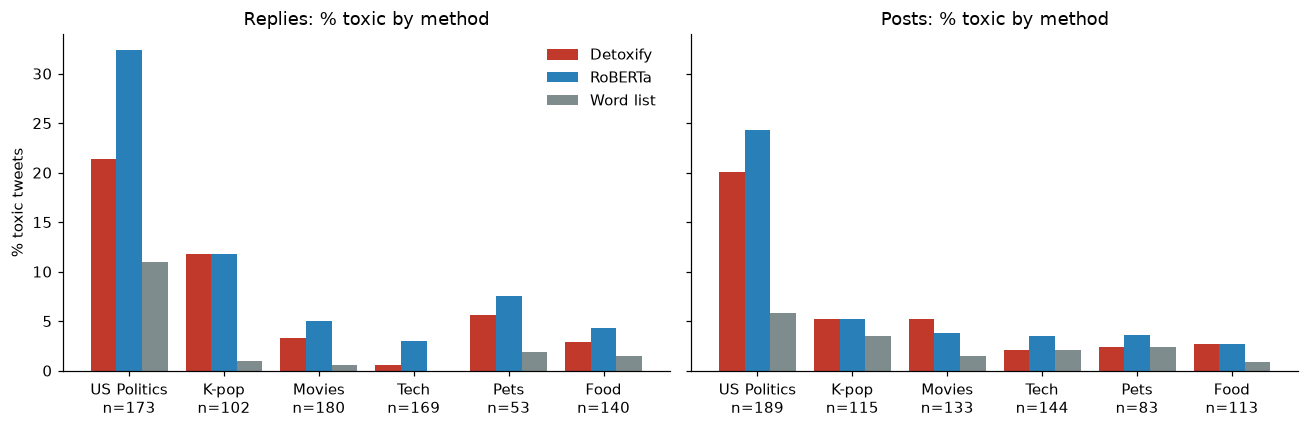

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)   # same y-axis, so the two panels compare directly
for ax, (kind, title) in zip(axes, [("reply", "Replies"), ("post", "Posts")]):
    pct = (scored[scored["type"] == kind].groupby("topic")[list(methods.values())].mean()
           .reindex(TOPIC_ORDER) * 100)
    for i, (name, color) in enumerate([("Detoxify", "#c0392b"), ("RoBERTa", "#2980b9"), ("Word list", "#7f8c8d")]):
        ax.bar(np.arange(6) + (i - 1) * 0.27, pct[methods[name]], 0.27, label=name, color=color)
    n = scored[scored["type"] == kind].groupby("topic").size()
    ax.set_xticks(np.arange(6), [f"{TOPIC_NAME[t]}\nn={n[t]}" for t in TOPIC_ORDER])
    ax.set_title(f"{title}: % toxic by method")
axes[0].set_ylabel("% toxic tweets")
axes[0].legend(frameon=False)
plt.tight_layout()
plt.savefig(FIG / "fig1_toxic_by_topic.png", bbox_inches="tight")
plt.show()

**What we see**

- **All three methods put US Politics first**, for replies and for posts. For replies: Detoxify 21.4%, RoBERTa 32.4%, word list 11.0%.
- **Detoxify and RoBERTa give the same order for replies:** US Politics > K-pop > Pets > Movies > Food > Tech. RoBERTa flags more tweets overall (160 vs 122).
- **The word list finds almost nothing outside politics:** 0–2 replies per topic (0–1.9%). So its order for the other 5 topics depends on 1 or 2 tweets.
- **Posts are closer together.** Apart from US Politics (20–24% with the AI models), all topics are between 2% and 5%, so their order can change with one tweet.

## 4. Question 1: Which topics are the most toxic?

**Replies are our main result**, because that's where people talk to each other. We answer in two steps:

1. **Threshold check.** We count toxic tweets per topic with Detoxify and RoBERTa at 3 thresholds: 0.3, 0.5 and 0.7. If the topic order stays about the same, the result doesn't depend on our choice of 0.5. The word list has no score, only a word count, so a threshold doesn't apply to it.
2. **Our guess vs. the data.** Our vote put 2 topics in each level, so we do the same with the data: sort the 6 topics by % toxic, then top 2 = **High**, middle 2 = **Mid**, bottom 2 = **Low**. The levels are relative because there is no standard cut-off (like "10% = High"), and the methods give very different %. Then we count how many topics match our guess.

In [30]:
def to_levels(pct):
    """Top 2 topics = High, middle 2 = Mid, bottom 2 = Low (the same way we voted)."""
    order = pct.sort_values(ascending=False, kind="stable").index   # most toxic first
    return pd.Series(["High"] * 2 + ["Mid"] * 2 + ["Low"] * 2, index=order)


def n_match(levels):
    return sum(levels[t] == GUESS[t] for t in TOPIC_ORDER)


SCORES = {"Detoxify": "detox_toxicity", "RoBERTa": "roberta_offensive"}
rows = []
for kind in ["reply", "post"]:
    g = scored[scored["type"] == kind]
    for name, col in SCORES.items():
        for t in [0.3, 0.5, 0.7]:
            pct = ((g[col] >= t).groupby(g["topic"]).mean() * 100).reindex(TOPIC_ORDER)
            rows.append({"type": kind, "method": name, "threshold": t,
                         **{TOPIC_NAME[x]: round(pct[x], 1) for x in TOPIC_ORDER},
                         "match": f"{n_match(to_levels(pct))}/6"})
print("% toxic per topic at each threshold")
pd.DataFrame(rows).set_index(["type", "method", "threshold"])

% toxic per topic at each threshold


US Politics  K-pop  Movies  Tech  Pets  Food match
type  method   threshold                                                    
reply Detoxify 0.3               24.3   12.7     6.1   1.2   5.7   3.6   4/6
               0.5               21.4   11.8     3.3   0.6   5.7   2.9   4/6
               0.7               18.5    7.8     2.8   0.0   3.8   1.4   4/6
      RoBERTa  0.3               50.9   23.5    16.1   5.3  24.5  12.9   3/6
               0.5               32.4   11.8     5.0   3.0   7.5   4.3   4/6
               0.7               19.1    7.8     1.1   1.2   1.9   0.7   4/6
post  Detoxify 0.3               23.3    6.1     5.3   2.8   3.6   2.7   4/6
               0.5               20.1    5.2     5.3   2.1   2.4   2.7   2/6
               0.7               18.0    4.3     5.3   2.1   2.4   1.8   2/6
      RoBERTa  0.3               40.7    6.1    12.0   4.2   8.4   3.5   2/6
               0.5               24.3    5.2     3.8   3.5   3.6   2.7   4/6
               0.7               13.8    4.3     0.8   1.4   2.4   0.9   4/6

In [31]:
def level_table(kind):
    """% toxic and data level per topic at the normal rule (models >= 0.5, list >= 1 bad word)."""
    g = scored[scored["type"] == kind]
    out = pd.DataFrame({"our guess": [GUESS[t] for t in TOPIC_ORDER]}, index=TOPIC_ORDER)
    matches = {"our guess": ""}
    for name, col in methods.items():   # Detoxify, RoBERTa, Word list
        pct = g.groupby("topic")[col].mean().reindex(TOPIC_ORDER) * 100
        levels = to_levels(pct)
        out[name] = [f"{pct[t]:.1f}% {levels[t]}" + (" ✓" if levels[t] == GUESS[t] else "") for t in TOPIC_ORDER]
        matches[name] = f"{n_match(levels)}/6"
    out.loc["matches"] = matches
    return out.rename(index=TOPIC_NAME)


print("Replies (✓ = same level as our guess)")
display(level_table("reply"))
print("Posts")
display(level_table("post"))

g = scored.groupby("type")["detox_toxic"].mean() * 100
print(f"All topics together (Detoxify): replies {g['reply']:.1f}% toxic, posts {g['post']:.1f}% toxic")

Replies (✓ = same level as our guess)


,our guess,Detoxify,RoBERTa,Word list
US Politics,High,21.4% High ✓,32.4% High ✓,11.0% High ✓
K-pop,High,11.8% High ✓,11.8% High ✓,1.0% Mid
Movies,Mid,3.3% Mid ✓,5.0% Mid ✓,0.6% Low
Tech,Mid,0.6% Low,3.0% Low,0.0% Low
Pets,Low,5.7% Mid,7.5% Mid,1.9% High
Food,Low,2.9% Low ✓,4.3% Low ✓,1.4% Mid
matches,,4/6,4/6,1/6


Posts


,our guess,Detoxify,RoBERTa,Word list
US Politics,High,20.1% High ✓,24.3% High ✓,5.8% High ✓
K-pop,High,5.2% Mid,5.2% High ✓,3.5% High ✓
Movies,Mid,5.3% High,3.8% Mid ✓,1.5% Low
Tech,Mid,2.1% Low,3.5% Low,2.1% Mid ✓
Pets,Low,2.4% Low ✓,3.6% Mid,2.4% Mid
Food,Low,2.7% Mid,2.7% Low ✓,0.9% Low ✓
matches,,2/6,4/6,4/6


All topics together (Detoxify): replies 7.7% toxic, posts 7.6% toxic


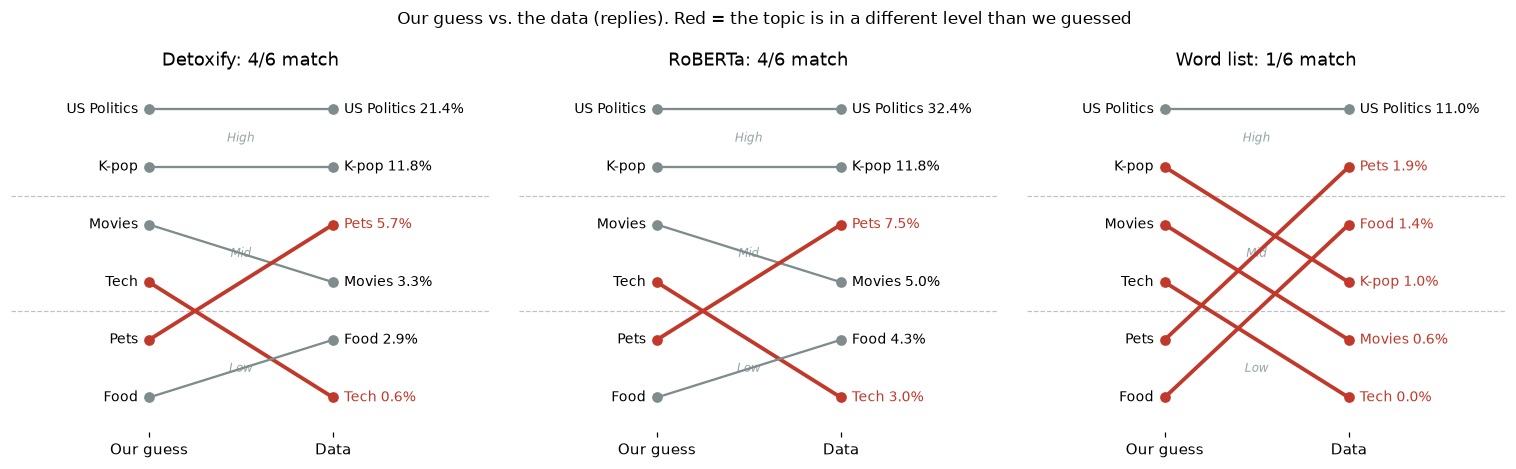

In [32]:
# Slope chart: our guess (left) vs. the data (right), replies.
# Dashed lines = the 2/2/2 cut (High / Mid / Low). Red line = the topic changed level.
reply = scored[scored["type"] == "reply"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, (name, col) in zip(axes, methods.items()):
    pct = reply.groupby("topic")[col].mean().reindex(TOPIC_ORDER) * 100
    levels = to_levels(pct)
    left = {t: i for i, t in enumerate(TOPIC_ORDER)}       # TOPIC_ORDER is already High, High, Mid, Mid, Low, Low
    right = {t: i for i, t in enumerate(levels.index)}     # most toxic first
    for t in TOPIC_ORDER:
        same = levels[t] == GUESS[t]
        ax.plot([0, 1], [left[t], right[t]], "-o", lw=1.5 if same else 2.5,
                color="#7f8c8d" if same else "#c0392b", zorder=3)
        ax.text(-0.06, left[t], TOPIC_NAME[t], ha="right", va="center", fontsize=9)
        ax.text(1.06, right[t], f"{TOPIC_NAME[t]} {pct[t]:.1f}%", ha="left", va="center", fontsize=9,
                color="black" if same else "#c0392b")
    for y in [1.5, 3.5]:
        ax.axhline(y, ls="--", lw=0.8, color="#bdc3c7", zorder=1)
    for y, lvl in [(0.5, "High"), (2.5, "Mid"), (4.5, "Low")]:
        ax.text(0.5, y, lvl, ha="center", va="center", fontsize=8, color="#95a5a6", style="italic",
                bbox={"facecolor": "white", "edgecolor": "none", "pad": 1}, zorder=2)
    ax.set_xlim(-0.75, 1.85)
    ax.set_xticks([0, 1], ["Our guess", "Data"])
    ax.set_title(f"{name}: {n_match(levels)}/6 match")
    ax.tick_params(left=False)
    for side in ["left", "bottom"]:
        ax.spines[side].set_visible(False)
axes[0].set_ylim(5.6, -0.6)
axes[0].set_yticks([])
fig.suptitle("Our guess vs. the data (replies). Red = the topic is in a different level than we guessed", fontsize=11)
plt.tight_layout()
plt.savefig(FIG / "fig2_guess_vs_data.png", bbox_inches="tight")
plt.show()

**What this shows**

- **US Politics is #1 in every case:** both models, all 3 thresholds, replies and posts.
- **Replies are stable.** Detoxify matches our guess 4/6 at every threshold, and RoBERTa 4/6 at 0.5 and 0.7. Both models miss the same 2 topics: Tech is less toxic than we guessed (Low, not Mid), and Pets is more toxic (Mid, not Low). The only change is RoBERTa at 0.3 (3/6), but 0.3 is too loose for RoBERTa: it flags half of all US Politics replies.
- **Posts are not stable (2–4/6).** Apart from US Politics, all topics are between 2% and 6%, so one tweet can change the order. For example, Detoxify at 0.5 has Movies (5.3%, 7 of 133) just above K-pop (5.2%, 6 of 115).
- **The word list matches only 1/6 for replies.** Outside politics it finds 0–2 bad-word replies per topic, so its ranking isn't reliable.

### Checking the surprises

Three results need a closer look before we trust them: K-pop in 2nd place, Pets being more toxic than we guessed, and whether 4/6 matches is actually good.

**1. K-pop: are the toxic replies spread out, or from one thread?** Each block is one thread (all replies under one post). The dark block is the biggest thread.

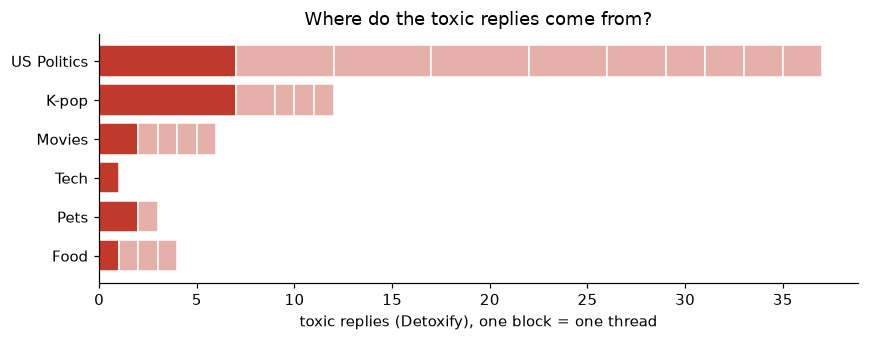

,toxic_replies,threads,biggest_thread
topic,,,
US Politics,37,10,7
K-pop,12,5,7
Movies,6,5,2
Tech,1,1,1
Pets,3,2,2
Food,4,4,1


In [33]:
tox_r = scored[(scored["type"] == "reply") & (scored["detox_toxic"] == 1)]

fig, ax = plt.subplots(figsize=(8, 3.2))
for y, t in enumerate(TOPIC_ORDER):
    left = 0
    for i, n in enumerate(tox_r.loc[tox_r["topic"] == t, "parent_id"].value_counts()):   # biggest thread first
        ax.barh(y, n, left=left, color="#c0392b" if i == 0 else "#e6b0aa", edgecolor="white")
        left += n
ax.set_yticks(range(len(TOPIC_ORDER)), [TOPIC_NAME[t] for t in TOPIC_ORDER])
ax.invert_yaxis()
ax.set_xlabel("toxic replies (Detoxify), one block = one thread")
ax.set_title("Where do the toxic replies come from?")
plt.tight_layout()
plt.show()

(tox_r.groupby("topic")["parent_id"].agg(toxic_replies="size", threads="nunique",
                                         biggest_thread=lambda x: x.value_counts().iloc[0])
      .reindex(TOPIC_ORDER).fillna(0).astype(int).rename(index=TOPIC_NAME))

**K-pop:** 7 of its 12 toxic replies are under **one post**. Without that thread, K-pop would have about 5, close to Pets and Movies. US Politics is different: its 37 toxic replies are spread over 10 threads, so its 1st place doesn't depend on one post.

**2. Pets: what do its toxic replies actually say?**

In [34]:
scored[(scored["topic"] == "pets") & (scored["type"] == "reply") & (scored["detox_toxic"] == 1)][
    ["detox_toxicity", "text_clean"]].round(2)

,detox_toxicity,text_clean
841,0.72,Such meanies! 😱💪💕
843,0.60,Slap the dog
910,0.99,Get over it cunt.


Only 3 replies, and "Such meanies! 😱💪💕" is playful, not toxic. Without it, Pets would be 2 of 53 (3.8%), just above Movies (3.3%) and Food (2.9%). So whether Pets is Mid or Low depends on one or two tweets.

**3. Is 4/6 a good match?** If we had put the 6 topics into 2 High, 2 Mid and 2 Low completely at random, how many would match? There are only 90 ways to do it, so we can try them all.

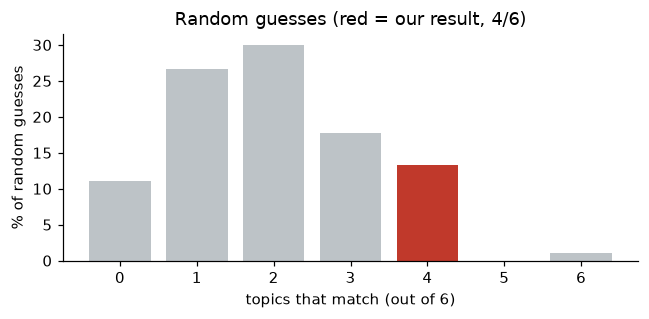

Random guess: 2/6 on average, 4/6 or better 14% of the time


In [35]:
from itertools import permutations

arrangements = set(permutations(["High"] * 2 + ["Mid"] * 2 + ["Low"] * 2))   # all 90 random guesses
chance = pd.Series([sum(a[i] == GUESS[t] for i, t in enumerate(TOPIC_ORDER)) for a in arrangements])
counts = chance.value_counts().reindex(range(7), fill_value=0)

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(counts.index, counts / len(chance) * 100, color=["#c0392b" if k == 4 else "#bdc3c7" for k in counts.index])
ax.set_xlabel("topics that match (out of 6)")
ax.set_ylabel("% of random guesses")
ax.set_title("Random guesses (red = our result, 4/6)")
plt.tight_layout()
plt.show()
print(f"Random guess: {chance.mean():.0f}/6 on average, 4/6 or better {100 * (chance >= 4).mean():.0f}% of the time")

A random guess gets 2/6 on average and 4/6 or better only 14% of the time. So our 4/6 is better than chance, but with only 6 topics it's a rough check, not proof.

**Answer to Question 1**

- **US Politics is the most toxic topic.** 21.4% of its replies are toxic (37 of 173, Detoxify), and it is #1 for every method and threshold.
- **K-pop is second** (11.8%, 12 of 102), but 7 of the 12 are under one post, so this mostly reflects one heated thread. The other four topics are all below 6%.
- **Tech is the least toxic** (0.6%, 1 of 169).
- **Our guess was mostly right:** 4/6 topics for replies, with both models and at every threshold (except RoBERTa at 0.3, 3/6). We guessed too high for Tech and too low for Pets. A random guess gets 2/6 on average, so 4/6 is better than chance, but only a rough check.

**Note on Pets.** We collected only 68 Pets replies (other topics had 139–226), and 53 are left after cleaning. Only 3 of them are toxic, so one tweet changes the % by about 2 points, and one of the 3 ("Such meanies! 😱💪💕") is playful, not toxic. So "Pets is more toxic than we guessed" is not a reliable result.

## 5. Question 2: What kind of toxicity?

For each toxic tweet, we take the type with the highest Detoxify score: obscene, insult, threat, identity attack or sexual. We skip `toxicity` and `severe_toxicity`, because they say *how* toxic, not *what kind*. Posts and replies are combined to get more tweets. Topics with a small n are not reliable.

In [36]:
TYPE_COLS = ["obscene", "insult", "threat", "identity_attack", "sexual_explicit"]
tox = scored[scored["detox_toxic"] == 1].copy()
tox["tox_type"] = [TYPE_COLS[i] for i in tox[[f"detox_{c}" for c in TYPE_COLS]].to_numpy().argmax(1)]
tox[["topic", "tox_type", "text_clean"]].head(3)

,topic,tox_type,text_clean
8,food,threat,ive decided to kill two characters in the final battle of my hunger games au so far #cooking
16,food,insult,One of the dumbest things we do as adults is grabbing or picking up something to see if it’s sti...
76,food,obscene,Damn these look so good! I’ll make these or have my son do it since he’s been the chef lately ☺️


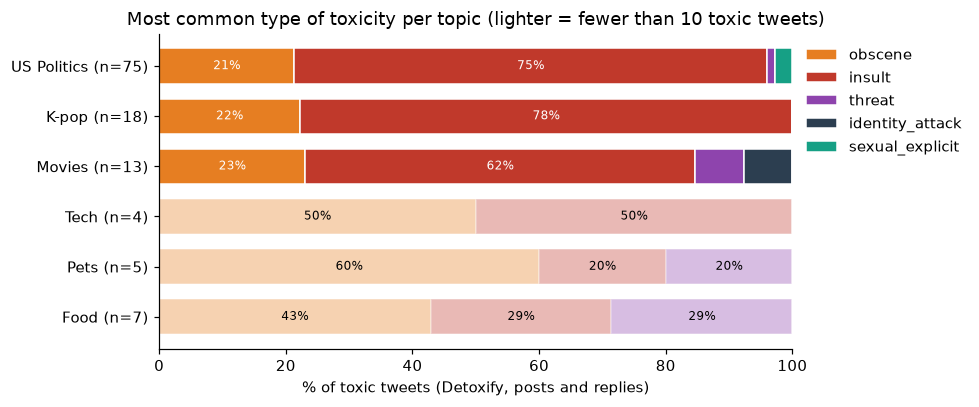

tox_type,obscene,insult,threat,identity_attack,sexual_explicit,n_toxic
topic,,,,,,
US Politics,21.0,75.0,1.0,0.0,3.0,75
K-pop,22.0,78.0,0.0,0.0,0.0,18
Movies,23.0,62.0,8.0,8.0,0.0,13
Tech,50.0,50.0,0.0,0.0,0.0,4
Pets,60.0,20.0,20.0,0.0,0.0,5
Food,43.0,29.0,29.0,0.0,0.0,7


In [37]:
types = pd.crosstab(tox["topic"], tox["tox_type"]).reindex(index=TOPIC_ORDER, columns=TYPE_COLS).fillna(0)
n_toxic = types.sum(axis=1).astype(int)
types_pct = types.div(n_toxic.replace(0, np.nan), axis=0) * 100
TYPE_COLOR = dict(zip(TYPE_COLS, ["#e67e22", "#c0392b", "#8e44ad", "#2c3e50", "#16a085"]))
SMALL = 10   # fewer toxic tweets than this = not reliable, drawn lighter

fig, ax = plt.subplots(figsize=(9, 3.8))
for y, t in enumerate(TOPIC_ORDER):
    left, alpha = 0, 0.35 if n_toxic[t] < SMALL else 1.0
    for c in TYPE_COLS:
        v = types_pct.loc[t, c]
        ax.barh(y, v, left=left, height=0.7, color=TYPE_COLOR[c], alpha=alpha, edgecolor="white",
                label=c if y == 0 else None)
        if v >= 12:
            ax.text(left + v / 2, y, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if alpha == 1 else "black")
        left += v
ax.set_yticks(range(6), [f"{TOPIC_NAME[t]} (n={n_toxic[t]})" for t in TOPIC_ORDER])
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("% of toxic tweets (Detoxify, posts and replies)")
ax.set_title(f"Most common type of toxicity per topic (lighter = fewer than {SMALL} toxic tweets)")
ax.legend(frameon=False, bbox_to_anchor=(1, 1), loc="upper left")
plt.tight_layout()
plt.savefig(FIG / "fig3_toxicity_types.png", bbox_inches="tight")
plt.show()
types_pct.round(0).assign(n_toxic=n_toxic).rename(index=TOPIC_NAME)

## 6. Question 3: What does the bad-word list miss?

We don't have human labels yet, so first we compare the methods with each other. This shows *where* they disagree, not who is right. The hand labels (6.4) will tell us who is right.

Cohen's kappa is agreement after removing lucky agreement (0 = chance, 1 = perfect).

In [38]:
methods = {"Word list": "bw_toxic", "Detoxify": "detox_toxic", "RoBERTa": "roberta_toxic"}
rows = []
for a, b in [("Word list", "Detoxify"), ("Word list", "RoBERTa"), ("Detoxify", "RoBERTa")]:
    x, y = scored[methods[a]], scored[methods[b]]
    rows.append({"pair": f"{a} vs {b}", "% agree": round(100 * (x == y).mean(), 1),
                 "kappa": round(cohen_kappa_score(x, y), 2)})
pd.DataFrame(rows)

,pair,% agree,kappa
0,Word list vs Detoxify,94.3,0.44
1,Word list vs RoBERTa,92.4,0.39
2,Detoxify vs RoBERTa,95.1,0.70


### 6.1 Misses: the model says toxic, but there is no bad word

In [39]:
miss = scored[(scored["detox_toxic"] == 1) & (scored["bw_toxic"] == 0)]
print(f"{len(miss)} of {scored['detox_toxic'].sum()} toxic tweets have no word from the list")
ex = miss.sample(min(5, len(miss)), random_state=SEED)
ex.assign(type=[TYPE_COLS[i] for i in ex[[f"detox_{c}" for c in TYPE_COLS]].to_numpy().argmax(1)])[
    ["topic", "type", "detox_toxicity", "text_clean"]].round(2)

83 of 122 toxic tweets have no word from the list


,topic,type,detox_toxicity,text_clean
772,movies,insult,0.84,OMG THEY'RE BABIESSSS
8,food,threat,0.59,ive decided to kill two characters in the final battle of my hunger games au so far #cooking
581,movies,insult,0.99,That's the problem right there. Batman should have been his first or second project along with S...
779,movies,obscene,0.63,i freaking need the zoom meeting video neowwww
417,kpop,obscene,0.84,listener request unlocked 🔥 JENNIE — Damn Right (feat. Childish Gambino & Kali Uchis) from Ruby ...


### 6.2 False alarms: a bad word is there, but the model says not toxic

In [40]:
fa = scored[(scored["bw_toxic"] == 1) & (scored["detox_toxic"] == 0)]
print(f"{len(fa)} of {scored['bw_toxic'].sum()} word-list hits are not toxic for Detoxify")
print("Most common words:", Counter(w for ws in fa["bw_words"] for w in ws.split("|") if w).most_common(8))
fa.sample(min(5, len(fa)), random_state=SEED)[["topic", "bw_words", "detox_toxicity", "text_clean"]].round(2)

8 of 47 word-list hits are not toxic for Detoxify
Most common words: [('🖕', 2), ('rapist', 2), ('sexy', 1), ('butt', 1), ('bollocks', 1), ('raping', 1), ('wet dream', 1)]


,topic,bw_words,detox_toxicity,text_clean
363,kpop,🖕,0.00,It went from 🖕 to 🫰. “Thank you BTS.” #BTSeffect #BTS
1069,tech,bollocks,0.13,Every update someone cooks up some made up bollocks they’ve turned this on and you should turn i...
239,food,sexy,0.03,"Justin, you’re sexy"
1446,us_politics,wet dream,0.49,Crazy right? Almost like it's a globalist wet dream!
420,kpop,rapist|rapist,0.47,"They say god impregnated Mary at 12 years old, unconsented. That makes him a pedo/rapist. Jesus ..."


### 6.3 Which words make the models say "toxic"?

The models give one score per tweet, not per word. To see which words matter, we **remove one word at a time and score the tweet again**. If the score drops a lot without a word, that word is a **trigger word**.

- We do this for every tweet the model calls toxic, and keep its **top 2 trigger words**. We skip small words like "the" and "to", @names, links and emoji.
- We measure the drop on the model's raw output, before it is turned into a 0–1 score. Otherwise a tweet with several bad words stays at 1.00 when one is removed, and shows no trigger at all.
- **Word size** = number of toxic tweets where the word is a trigger. **Grey** = on the bad-word list. **Red** = not on the list, so the list misses it.

This is slow (about 8 minutes), so we save the result to `data/trigger_words.csv` and reuse it.

In [41]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

TRIGGERS = DATA / "trigger_words.csv"
MODELS = {"Detoxify": (DETOX_ID, "detox_toxic"), "RoBERTa": (ROBERTA_ID, "roberta_toxic")}
SKIP = ENGLISH_STOP_WORDS | {"user", "http", "amp", "rt"}


def norm_word(w):
    """'Shit.' -> 'shit'. Returns '' for words we skip."""
    w = w.lower().strip(".,!?;:\"()[]…“”‘’-").lstrip("#")
    if not re.search("[a-z]", w) or "'" in w or "’" in w or w in SKIP:
        return ""
    return w


def find_triggers(name, model_id, tweets, top_n=2):
    import torch
    from transformers import AutoModelForSequenceClassification, AutoTokenizer

    tok = AutoTokenizer.from_pretrained(model_id)
    model = AutoModelForSequenceClassification.from_pretrained(model_id).eval()

    def raw_score(texts):   # model output before the 0-1 squashing
        with torch.no_grad():
            lg = model(**tok(texts, padding=True, truncation=True, max_length=128, return_tensors="pt")).logits
        # Detoxify: column 0 is "toxicity". RoBERTa: "offensive" minus "non-offensive".
        return (lg[:, 0] if name == "Detoxify" else lg[:, 1] - lg[:, 0]).numpy()

    rows, t0 = [], time.time()
    for tid, text in zip(tweets["tweet_id"], tweets["text_model"]):
        words = text.split()
        scores = raw_score([text] + [" ".join(words[:i] + words[i + 1:]) for i in range(len(words))])
        drop = {}
        for w, d in zip(words, scores[0] - scores[1:]):
            w = norm_word(w)
            if w and d > 0:
                drop[w] = max(d, drop.get(w, 0))
        for w, d in sorted(drop.items(), key=lambda x: -x[1])[:top_n]:
            rows.append({"model": name, "tweet_id": tid, "word": w, "drop": round(float(d), 3)})
    print(f"{name}: {len(tweets)} toxic tweets in {time.time() - t0:.0f}s")
    return rows


trig = None
if TRIGGERS.exists() and TRIGGERS.stat().st_mtime > SCORED.stat().st_mtime:   # saved after the last scoring
    trig = pd.read_csv(TRIGGERS, dtype={"tweet_id": str})
    print(f"Loaded saved trigger words. Delete {TRIGGERS} to compute again.")
if trig is None:
    rows = []
    for name, (model_id, col) in MODELS.items():
        rows += find_triggers(name, model_id, scored[scored[col] == 1])
    trig = pd.DataFrame(rows)
    trig.to_csv(TRIGGERS, index=False, encoding="utf-8")

trig["on_list"] = trig["word"].isin(BW_SINGLE)
top = {name: g.groupby("word").agg(tweets=("tweet_id", "size"), on_list=("on_list", "first"))
              .sort_values("tweets", ascending=False).head(15).reset_index()
       for name, g in trig.groupby("model")}
pd.concat(top, axis=1)

Loaded saved trigger words. Delete data\trigger_words.csv to compute again.


Detoxify                   RoBERTa               
           word tweets on_list       word tweets on_list
0          fuck      9    True       fuck      9    True
1       fucking      6    True    fucking      7    True
2        stupid      6   False  democrats      6   False
3          hell      5   False     stupid      6   False
4     democrats      5   False       hell      5   False
5      bullshit      4    True        ass      5    True
6   republicans      4   False       shit      4    True
7          shit      4    True      bitch      4    True
8      pathetic      4   False     fucked      3   False
9    disgusting      3   False    fascist      3   False
10         cunt      3    True   bullshit      3    True
11        bitch      3    True        man      3   False
12          ass      3    True      needs      3   False
13         damn      3   False        men      3   False
14       fucked      3   False   criminal      3   False

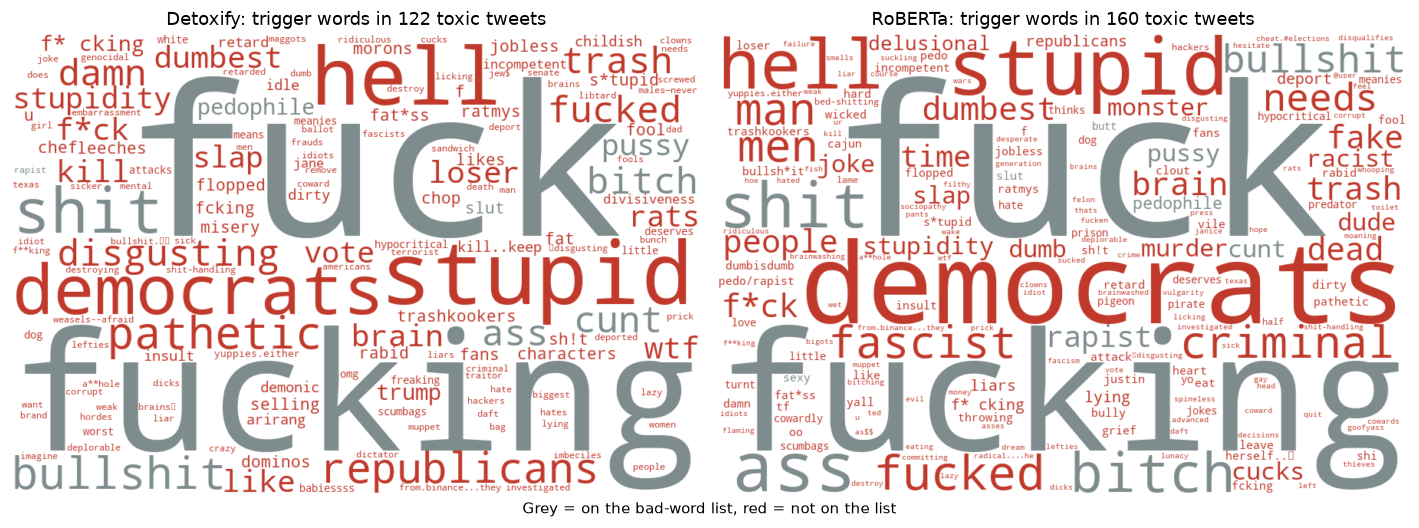

Trigger words that are NOT on the bad-word list: Detoxify 83%, RoBERTa 86%


In [42]:
from wordcloud import WordCloud


def list_color(word, **kwargs):
    return "#7f8c8d" if word in BW_SINGLE else "#c0392b"   # grey = on the list, red = the list misses it


fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, name in zip(axes, MODELS):
    g = trig[trig["model"] == name]
    wc = WordCloud(width=900, height=600, background_color="white", color_func=list_color,
                   prefer_horizontal=1.0, random_state=SEED).generate_from_frequencies(g["word"].value_counts().to_dict())
    ax.imshow(wc, interpolation="bilinear")
    ax.axis("off")
    ax.set_title(f"{name}: trigger words in {g['tweet_id'].nunique()} toxic tweets")
fig.suptitle("Grey = on the bad-word list, red = not on the list", y=0.02, fontsize=10)
plt.tight_layout()
plt.savefig(FIG / "fig4_trigger_words.png", bbox_inches="tight")
plt.show()

on = trig.groupby("model")["on_list"].mean() * 100
print("Trigger words that are NOT on the bad-word list: "
      + ", ".join(f"{name} {100 - on[name]:.0f}%" for name in MODELS))

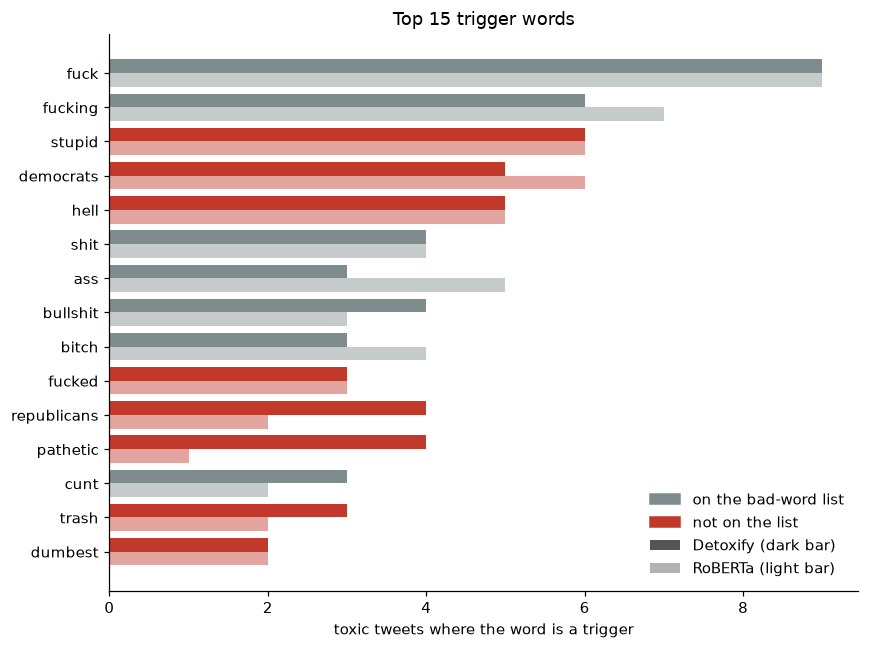

model,Detoxify,RoBERTa,on_list
word,,,
fuck,9,9,True
fucking,6,7,True
stupid,6,6,False
democrats,5,6,False
hell,5,5,False
shit,4,4,True
ass,3,5,True
bullshit,4,3,True
bitch,3,4,True


In [43]:
# Top 15 trigger words over both models. Bar length = toxic tweets where the word is a trigger.
counts = trig.groupby(["word", "model"])["tweet_id"].nunique().unstack("model").reindex(columns=list(MODELS)).fillna(0)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index[:15]]

fig, ax = plt.subplots(figsize=(8, 6))
y = np.arange(len(counts))
for i, (name, style) in enumerate([("Detoxify", {}), ("RoBERTa", {"alpha": 0.45})]):
    ax.barh(y + (i - 0.5) * 0.4, counts[name], 0.4,
            color=["#7f8c8d" if w in BW_SINGLE else "#c0392b" for w in counts.index], **style)
ax.set_yticks(y, counts.index)
ax.invert_yaxis()
ax.set_xlabel("toxic tweets where the word is a trigger")
ax.set_title("Top 15 trigger words")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#7f8c8d", label="on the bad-word list"),
                   Patch(color="#c0392b", label="not on the list"),
                   Patch(facecolor="#555555", label="Detoxify (dark bar)"),
                   Patch(facecolor="#555555", alpha=0.45, label="RoBERTa (light bar)")],
          frameon=False, loc="lower right")
plt.tight_layout()
plt.savefig(FIG / "fig4b_trigger_words_bar.png", bbox_inches="tight")
plt.show()
counts.astype(int).assign(on_list=[w in BW_SINGLE for w in counts.index])

**What we see**

- **Most trigger words are not on the list:** 83% for Detoxify and 86% for RoBERTa. The biggest group is ordinary insults without swearing: *stupid, pathetic, trash, dumbest, disgusting*.
- **The list misses other forms of a word.** *fuck* and *fucking* are on the list, but *fucked* is not. *hell* and *damn* aren't on it either.
- **Clear swear words are triggers for both models** (*fuck, shit, bitch, ass*), so on obvious swearing the list and the models agree.
- **Detoxify and RoBERTa mostly pick the same words**, which fits their good agreement (kappa 0.70).
- **"democrats" and "republicans" are triggers** in 2–6 US Politics tweets. They are our search hashtags, not insults, but the score drops when the party name is removed. So the models partly react to the group name itself, or to an insult being aimed at a group. This is a known weakness of toxicity models and may make US Politics look slightly more toxic. These two words are red only because the list (correctly) doesn't contain them.

### 6.4 Hand-label sheet

To know which method is right, two of us label the same 250 tweets by hand.

- Only about 1 in 9 tweets is flagged by any method, so a random 250 would have very few toxic tweets. We take **half flagged and half not flagged**, spread over the topics.
- The sheet shows only the text (and the post it replies to). There's no topic and no score, so we aren't influenced.
- Each labeler fills `toxic` (1 or 0) and, if toxic, `type` (insult, obscene, threat, identity_attack, sexual). Then saves it as `label_sheet_A_filled.csv` or `label_sheet_B_filled.csv` in `data/labels/`.

In [44]:
LABELS.mkdir(parents=True, exist_ok=True)
KEY = LABELS / "label_key.csv"
any_flag = scored[["bw_toxic", "detox_toxic", "roberta_toxic"]].max(axis=1)
print(f"Flagged by at least one method: {100 * any_flag.mean():.1f}%")


def stratified(pool, n_total):
    per_topic = math.ceil(n_total / len(TOPIC_ORDER))
    got = pd.concat([g.sample(min(per_topic, len(g)), random_state=SEED) for _, g in pool.groupby("topic")])
    if len(got) < n_total:
        rest = pool.drop(got.index)
        got = pd.concat([got, rest.sample(min(n_total - len(got), len(rest)), random_state=SEED)])
    return got.sample(min(n_total, len(got)), random_state=SEED)


if KEY.exists():
    print("Label sheets already exist, not overwritten.")
else:
    sample = pd.concat([stratified(scored[any_flag == 1], 125).assign(stratum="flagged"),
                        stratified(scored[any_flag == 0], 125).assign(stratum="not_flagged")])
    sample = sample.sample(frac=1, random_state=SEED).reset_index(drop=True)
    sample["label_id"] = [f"L{i:03d}" for i in range(1, len(sample) + 1)]
    sheet = pd.DataFrame({"label_id": sample["label_id"],
                          "replying_to": np.where(sample["type"] == "reply", sample["parent_clean"], ""),
                          "text": sample["text_clean"], "toxic": "", "type": ""})
    for who in ["A", "B"]:
        sheet.to_csv(LABELS / f"label_sheet_{who}.csv", index=False, encoding="utf-8-sig")
    sample[["label_id", "tweet_id", "stratum"]].to_csv(KEY, index=False)
    print(f"Wrote label_sheet_A.csv, label_sheet_B.csv and label_key.csv in {LABELS}")

Flagged by at least one method: 11.5%
Label sheets already exist, not overwritten.


### 6.5 Check the methods against the hand labels

This runs when both filled sheets exist. We use the tweets where both labelers agree. If you settle the disagreements together, save them as `label_resolved.csv` (columns `label_id, toxic`).

**Precision:** when a method says toxic, how often is it right? **Recall:** of the really toxic tweets, how many does it find? The sample has more flagged tweets than real X, so these numbers describe this sample.

In [45]:
FA, FB, RES = (LABELS / "label_sheet_A_filled.csv", LABELS / "label_sheet_B_filled.csv",
               LABELS / "label_resolved.csv")
if not (FA.exists() and FB.exists()):
    print("No hand labels yet. Fill the two sheets, save them as *_filled.csv, and run this cell again.")
else:
    a = pd.read_csv(FA, encoding="utf-8-sig")[["label_id", "toxic"]]
    b = pd.read_csv(FB, encoding="utf-8-sig")[["label_id", "toxic"]]
    lab = a.merge(b, on="label_id", suffixes=("_A", "_B")).dropna()
    lab[["toxic_A", "toxic_B"]] = lab[["toxic_A", "toxic_B"]].astype(int)
    print(f"Labelers agree on {100 * (lab.toxic_A == lab.toxic_B).mean():.0f}% "
          f"(kappa = {cohen_kappa_score(lab.toxic_A, lab.toxic_B):.2f})")
    lab["gold"] = np.where(lab.toxic_A == lab.toxic_B, lab.toxic_A, np.nan)
    if RES.exists():
        lab["gold"] = lab["gold"].fillna(lab["label_id"].map(pd.read_csv(RES).set_index("label_id")["toxic"]))
    print(f"Left out (disagree): {lab['gold'].isna().sum()}")
    lab = (lab.dropna(subset=["gold"]).merge(pd.read_csv(KEY, dtype={"tweet_id": str}), on="label_id")
              .merge(scored[["tweet_id", *methods.values()]], on="tweet_id"))
    print(f"{len(lab)} labelled tweets, {int(lab['gold'].sum())} toxic")
    rows = []
    for name, col in methods.items():
        p, r, f, _ = precision_recall_fscore_support(lab["gold"].astype(int), lab[col],
                                                     average="binary", zero_division=0)
        rows.append({"method": name, "precision": round(p, 2), "recall": round(r, 2), "F1": round(f, 2)})
    display(pd.DataFrame(rows))

No hand labels yet. Fill the two sheets, save them as *_filled.csv, and run this cell again.


## 7. Extra: What do toxic tweets talk about? (LDA)

We put all toxic tweets together (each topic alone has too few) and look for 5 themes. We remove our 18 search hashtags first, otherwise LDA just finds them again. With only a few hundred tweets, the themes are rough, so take them as hints.

In [46]:
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

stop = list(ENGLISH_STOP_WORDS | set(SEED_TAGS) | {"user", "http", "amp", "rt", "just", "like",
                                                   "don", "im", "dont", "u", "ur", "lol"})
tox_any = scored[(scored["detox_toxic"] == 1) | (scored["roberta_toxic"] == 1)].copy()
vec = CountVectorizer(stop_words=stop, token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z]+\b", min_df=3, max_df=0.4)
X = vec.fit_transform(tox_any["text_clean"].str.lower())
lda = LatentDirichletAllocation(n_components=5, random_state=SEED)
doc_topic = lda.fit_transform(X)
vocab = np.array(vec.get_feature_names_out())

print(f"{len(tox_any)} toxic tweets, {len(vocab)} words\n")
for k, comp in enumerate(lda.components_):
    print(f"Theme {k + 1}: {', '.join(vocab[comp.argsort()[::-1][:10]])}")

180 toxic tweets, 121 words

Theme 1: ass, make, people, right, jennie, fake, good, crazy, job, say
Theme 2: people, country, bullshit, want, israel, fraud, know, won, album, making
Theme 3: trump, maga, gop, vote, stupid, didn, shit, people, party, going
Theme 4: needs, fuck, globalist, america, people, know, government, far, children, schumer
Theme 5: yes, men, got, watch, real, disgusting, fucking, woman, needs, people


Which theme shows up most in each topic?

In [47]:
tox_any["theme"] = doc_topic.argmax(1) + 1
(pd.crosstab(tox_any["topic"], tox_any["theme"], normalize="index") * 100) \
    .reindex(TOPIC_ORDER).rename(index=TOPIC_NAME).round(0)

theme,1,2,3,4,5
topic,,,,,
US Politics,31.0,14.0,26.0,14.0,16.0
K-pop,52.0,22.0,9.0,4.0,13.0
Movies,47.0,26.0,0.0,11.0,16.0
Tech,40.0,10.0,30.0,20.0,0.0
Pets,29.0,0.0,71.0,0.0,0.0
Food,58.0,17.0,17.0,8.0,0.0


## 8. Summary for the report

| Question | Answer |
|---|---|
| Most toxic topic (replies) | |
| Least toxic topic (replies) | |
| Are replies more toxic than posts? | |
| Does the ranking match our guess? | |
| Most common type of toxicity | |
| What the word list misses | |
| Best method on the hand labels (F1) | |

The figures are in `figures/`.